<a href="https://colab.research.google.com/github/mustaphaismail225-beep/prediction-taux-interet/blob/main/phase2_visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prédiction du taux d'intérêt d'un prêt bancaire
## Phase 2 : Visualisation des données et choix du modèle

**Auteur :** Mustapha Ismail – Bootcamp Data Scientist GoMyCode

**Données :** 395 207 prêts nettoyés lors de la phase 1.

### Démarche
1. **Distribution du taux** : le taux varie de 5,3 % à 31 % (moyenne 13,6 %), avec des pics liés à la grille de taux de la banque.
2. **Corrélations** : la durée du prêt est la variable la plus liée au taux (0,43), suivie de l'utilisation du crédit (0,29) et du ratio prêt / revenu (0,24).
3. **Multicolinéarité** : aucune paire de variables ne dépasse 0,8, donc toutes les variables sont gardées.
4. **Variables catégorielles** : la durée et l'objet du prêt créent les plus grands écarts de taux (environ 4,5 points).
5. **Relations non linéaires** : le taux varie selon l'année (pic en 2013), alors que l'ancienneté professionnelle n'a presque aucun effet (0,2 point).
6. **Valeurs manquantes** : je supprime `emp_length` (aucun effet et 4,6 % de manquants) ; `mort_acc` est imputée par la médiane dans un pipeline, sans fuite de données.
7. **Baseline** : un modèle qui prédit toujours la moyenne fait une erreur moyenne de 3,59 points.
8. **Comparaison de modèles** : régression linéaire, arbre de décision et forêt aléatoire, en validation croisée à 5 plis.
9. **Choix du modèle** : la forêt aléatoire est la meilleure (MAE 2,58 ; R² 0,46). Elle sera optimisée en phase 3.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensions : (395207, 20)


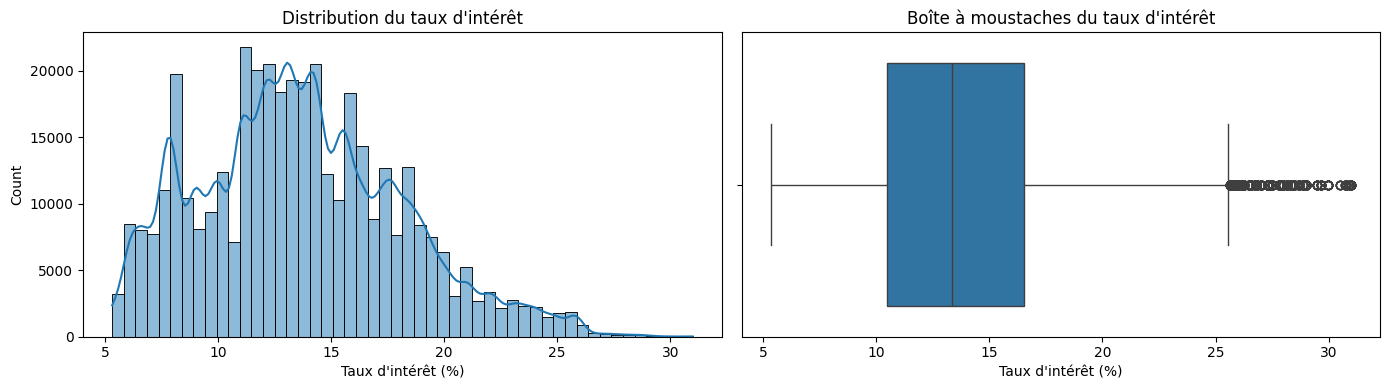

count    395207.00
mean         13.64
std           4.47
min           5.32
25%          10.49
50%          13.33
75%          16.55
max          30.99
Name: int_rate, dtype: float64
Asymétrie : 0.42


In [8]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

chemin = "/content/drive/MyDrive/Projet_Taux_Interet/data/"
df_fe = pd.read_parquet(chemin + "df_fe_phase1.parquet")
print("Dimensions :", df_fe.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_fe["int_rate"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution du taux d'intérêt")
axes[0].set_xlabel("Taux d'intérêt (%)")

sns.boxplot(x=df_fe["int_rate"], ax=axes[1])
axes[1].set_title("Boîte à moustaches du taux d'intérêt")
axes[1].set_xlabel("Taux d'intérêt (%)")

plt.tight_layout()
plt.show()

print(df_fe["int_rate"].describe().round(2))
print("Asymétrie :", round(df_fe["int_rate"].skew(), 2))

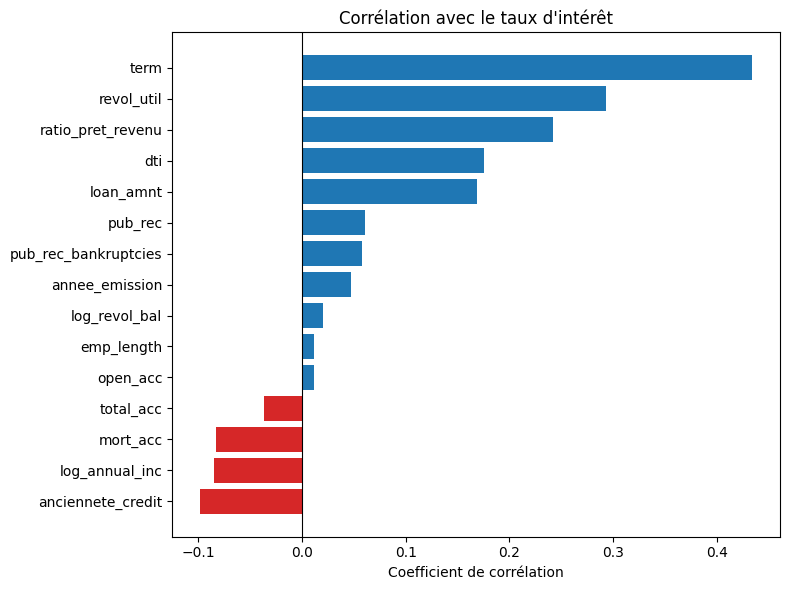

term                    0.434
revol_util              0.294
ratio_pret_revenu       0.242
dti                     0.176
loan_amnt               0.169
pub_rec                 0.061
pub_rec_bankruptcies    0.058
annee_emission          0.047
log_revol_bal           0.020
emp_length              0.012
open_acc                0.012
total_acc              -0.037
mort_acc               -0.083
log_annual_inc         -0.084
anciennete_credit      -0.099
Name: int_rate, dtype: float64


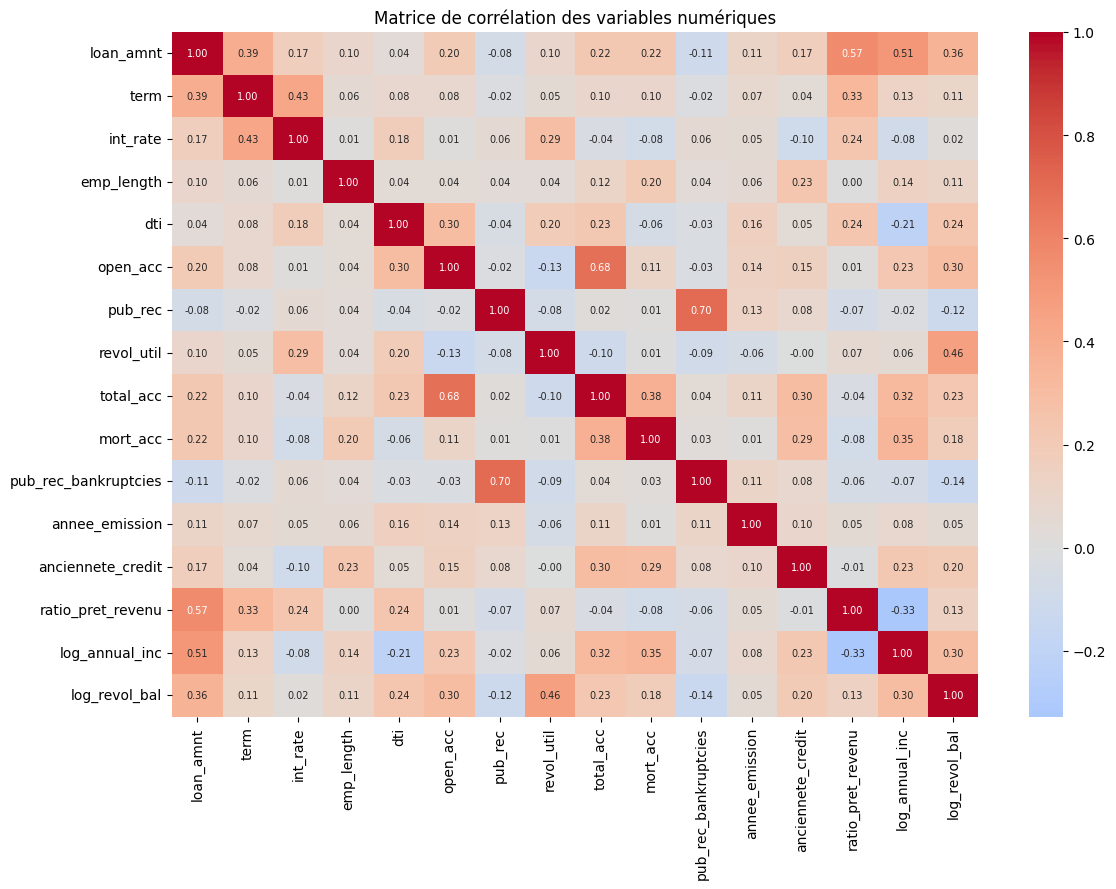

In [9]:
num_cols = df_fe.select_dtypes("number").columns
corr = df_fe[num_cols].corr()

# 1) Corrélation de chaque variable avec le taux
corr_cible = corr["int_rate"].drop("int_rate").sort_values()

plt.figure(figsize=(8, 6))
couleurs = ["tab:red" if v < 0 else "tab:blue" for v in corr_cible]
plt.barh(corr_cible.index, corr_cible.values, color=couleurs)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Corrélation avec le taux d'intérêt")
plt.xlabel("Coefficient de corrélation")
plt.tight_layout()
plt.show()

print(corr_cible.round(3).sort_values(ascending=False))

# 2) Heatmap de toutes les corrélations
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

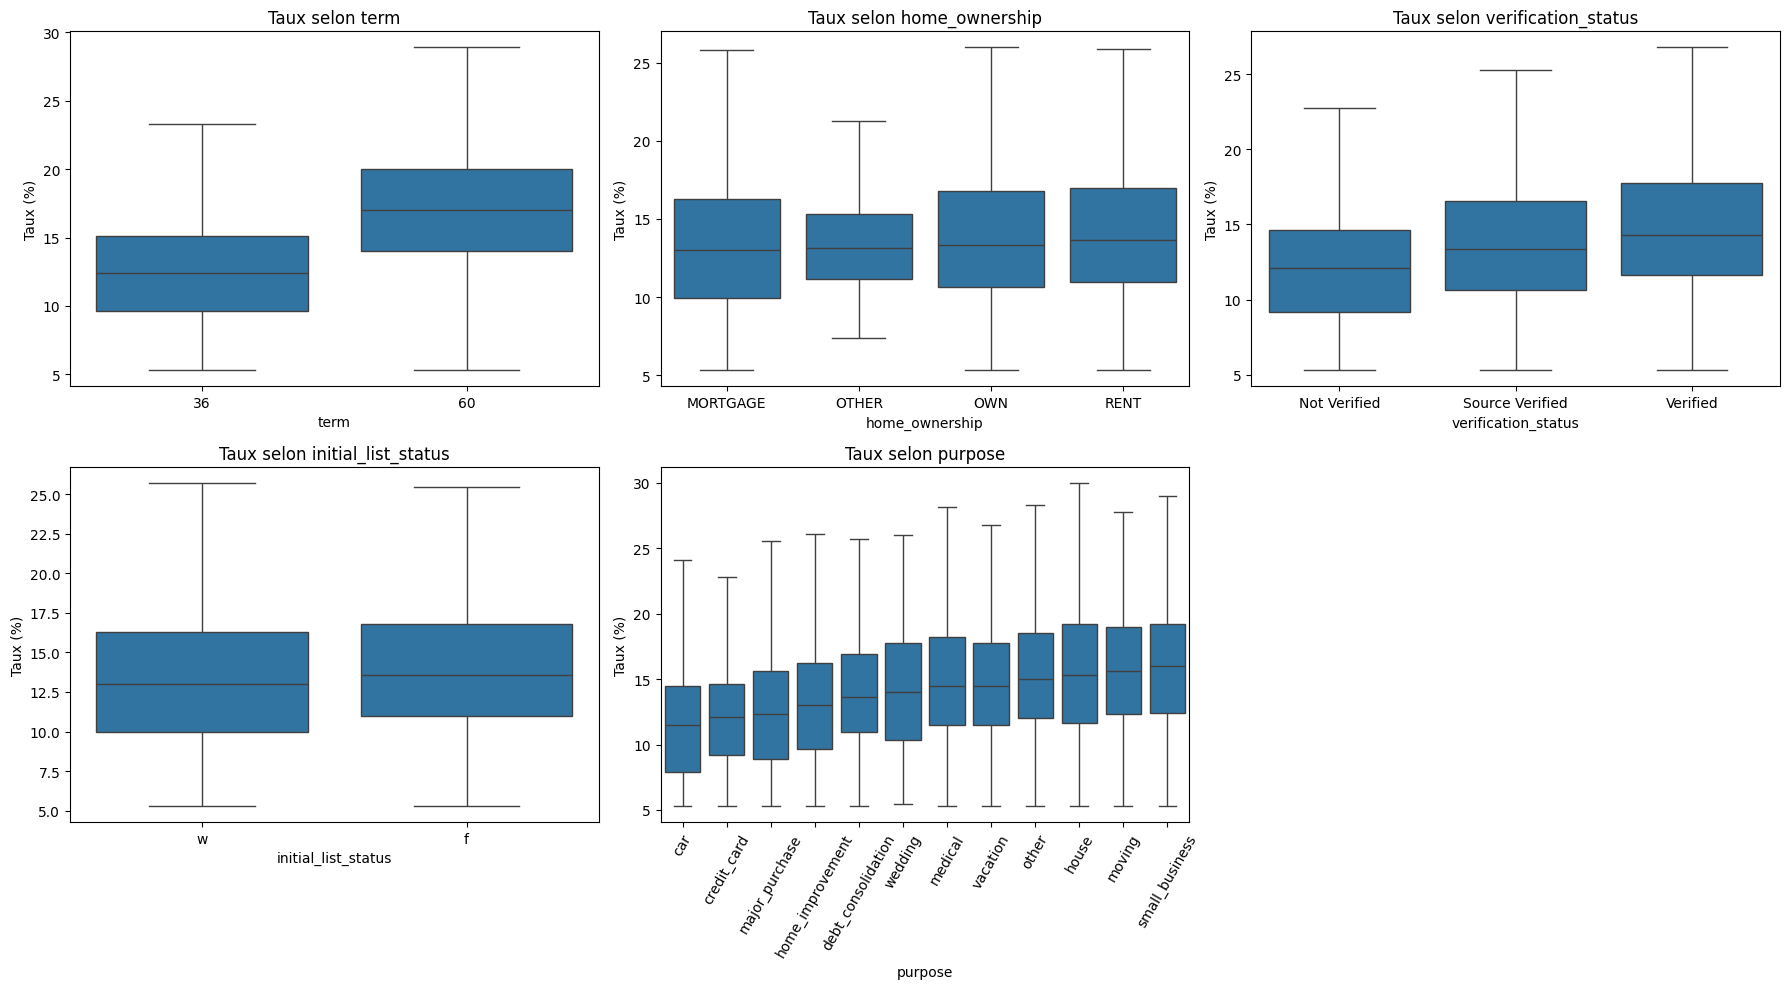


term :
term
36    12.42
60    16.99
Name: int_rate, dtype: float64

home_ownership :
home_ownership
MORTGAGE    12.99
OTHER       13.11
OWN         13.35
RENT        13.67
Name: int_rate, dtype: float64

verification_status :
verification_status
Not Verified       12.12
Source Verified    13.35
Verified           14.33
Name: int_rate, dtype: float64

initial_list_status :
initial_list_status
w    12.99
f    13.57
Name: int_rate, dtype: float64

purpose :
purpose
car                   11.49
credit_card           12.12
major_purchase        12.35
home_improvement      12.99
debt_consolidation    13.67
wedding               13.99
medical               14.48
vacation              14.49
other                 14.98
house                 15.31
moving                15.59
small_business        16.00
Name: int_rate, dtype: float64


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

variables = ["term", "home_ownership", "verification_status", "initial_list_status"]
for i, col in enumerate(variables):
    ordre = df_fe.groupby(col)["int_rate"].median().sort_values().index
    sns.boxplot(data=df_fe, x=col, y="int_rate", order=ordre, ax=axes[i], showfliers=False)
    axes[i].set_title(f"Taux selon {col}")
    axes[i].set_ylabel("Taux (%)")

ordre_purpose = df_fe.groupby("purpose")["int_rate"].median().sort_values().index
sns.boxplot(data=df_fe, x="purpose", y="int_rate", order=ordre_purpose, ax=axes[4], showfliers=False)
axes[4].set_title("Taux selon purpose")
axes[4].set_ylabel("Taux (%)")
axes[4].tick_params(axis="x", rotation=60)

axes[5].axis("off")
plt.tight_layout()
plt.show()

for col in variables + ["purpose"]:
    print(f"\n{col} :")
    print(df_fe.groupby(col)["int_rate"].median().sort_values().round(2))

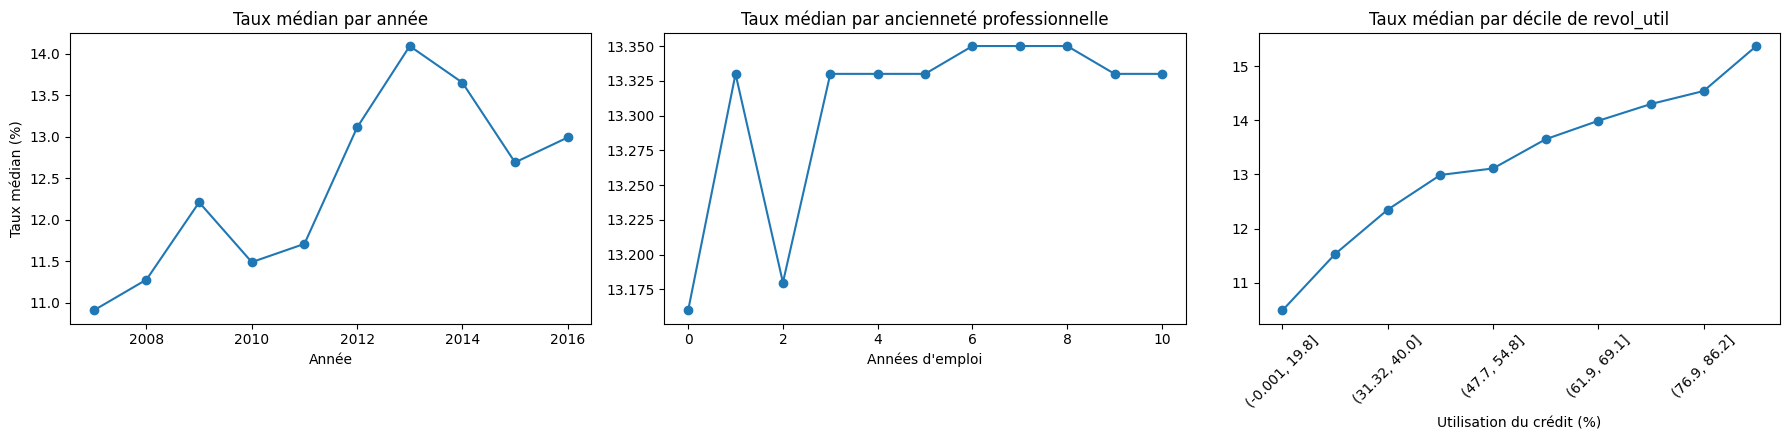

                median   count
annee_emission                
2007             10.91       5
2008             11.28     889
2009             12.21    3813
2010             11.49    9241
2011             11.71   17427
2012             13.11   41169
2013             14.09   97597
2014             13.65  102792
2015             12.69   94212
2016             12.99   28062


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Par année
df_fe.groupby("annee_emission")["int_rate"].median().plot(marker="o", ax=axes[0])
axes[0].set_title("Taux médian par année")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Taux médian (%)")

# 2) Par ancienneté professionnelle
df_fe.groupby("emp_length")["int_rate"].median().plot(marker="o", ax=axes[1])
axes[1].set_title("Taux médian par ancienneté professionnelle")
axes[1].set_xlabel("Années d'emploi")

# 3) Par déciles de revol_util
deciles = pd.qcut(df_fe["revol_util"], q=10)
df_fe.groupby(deciles, observed=True)["int_rate"].median().plot(marker="o", ax=axes[2])
axes[2].set_title("Taux médian par décile de revol_util")
axes[2].set_xlabel("Utilisation du crédit (%)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(df_fe.groupby("annee_emission")["int_rate"].agg(["median", "count"]).round(2))

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df_model = pd.read_parquet(chemin + "df_model_phase1.parquet")
df_model = df_model.drop(columns=["emp_length"])

X = df_model.drop(columns="int_rate")
y = df_model["int_rate"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)

print("\nBaseline (toujours la moyenne) :")
print("MAE  :", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R²   :", round(r2_score(y_test, y_pred), 3))

Train : (316165, 31) | Test : (79042, 31)

Baseline (toujours la moyenne) :
MAE  : 3.592
RMSE : 4.485
R²   : -0.0


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
import time

X_ech = X_train.sample(50000, random_state=42)
y_ech = y_train.loc[X_ech.index]

modeles = {
    "Régression linéaire": LinearRegression(),
    "Arbre de décision": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42)
}

resultats = []
for nom, modele in modeles.items():
    pipe = Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("echelle", StandardScaler()),
        ("modele", modele)
    ])
    debut = time.time()
    cv = cross_validate(pipe, X_ech, y_ech, cv=5,
                        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    resultats.append({
        "Modèle": nom,
        "MAE": -cv["test_neg_mean_absolute_error"].mean(),
        "RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "R²": cv["test_r2"].mean(),
        "R² écart-type": cv["test_r2"].std(),
        "Temps (s)": time.time() - debut
    })
    print(nom, "✅")

pd.DataFrame(resultats).round(3)

Régression linéaire ✅
Arbre de décision ✅
Forêt aléatoire ✅


,Modèle,MAE,RMSE,R²,R² écart-type,Temps (s)
0,Régression linéaire,2.746,3.439,0.403,0.006,0.731
1,Arbre de décision,2.846,3.613,0.341,0.009,2.214
2,Forêt aléatoire,2.583,3.259,0.464,0.007,82.323


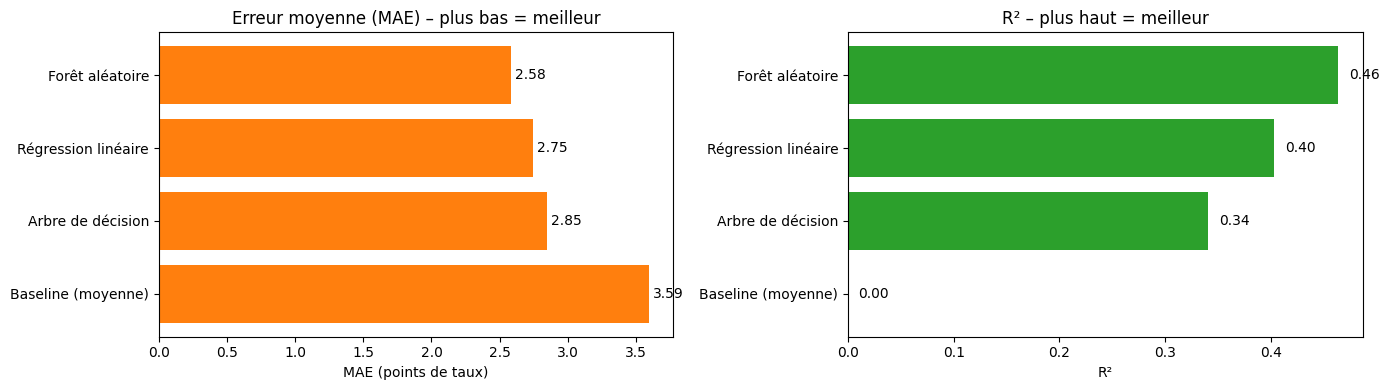

In [14]:
comparaison = pd.DataFrame(resultats)[["Modèle", "MAE", "R²"]]
comparaison.loc[len(comparaison)] = ["Baseline (moyenne)", 3.592, 0.0]
comparaison = comparaison.sort_values("MAE", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].barh(comparaison["Modèle"], comparaison["MAE"], color="tab:orange")
axes[0].set_title("Erreur moyenne (MAE) – plus bas = meilleur")
axes[0].set_xlabel("MAE (points de taux)")
for i, v in enumerate(comparaison["MAE"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}", va="center")

axes[1].barh(comparaison["Modèle"], comparaison["R²"], color="tab:green")
axes[1].set_title("R² – plus haut = meilleur")
axes[1].set_xlabel("R²")
for i, v in enumerate(comparaison["R²"]):
    axes[1].text(v + 0.01, i, f"{v:.2f}", va="center")

plt.tight_layout()
plt.show()